<a href="https://colab.research.google.com/github/shanesimmons812/comp-project/blob/q1-analysis/py/Q1_folder/Q1_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Question 1: Traditional machine learning

This first notebook investigates the performance of a traditional machine learning model of a selected dataset i choose. This uses a non-neural network approach, and its performance is evaluated. The dataset used is the Stellar Classification Dataset from the Sloan Digital Sky Survey (SDSS).An objective is to classify astronomical objects and evaluate the performance of a non-neural-network machine learning model.

In [7]:
!pip install -q kagglehub

importing the libraries

In [8]:
import kagglehub
import pandas as pd
import os

downloading the dataset of the stellar classifications from kaggle using the kagglehub

In [11]:
path = kagglehub.dataset_download(
    "fedesoriano/stellar-classification-dataset-sdss17"
)

print(path)

Using Colab cache for faster access to the 'stellar-classification-dataset-sdss17' dataset.
/kaggle/input/stellar-classification-dataset-sdss17


loadiing the dataset into pandas therefore can then be used for analyisis

In [14]:
for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            csv_file = os.path.join(root, file)
            print(csv_file)

df = pd.read_csv(csv_file)

/kaggle/input/stellar-classification-dataset-sdss17/star_classification.csv


exploring this dataset, the next few cells are giving overview of data and structure


In [17]:
df.head(11)


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842
5,1.237680e+18,340.995121,20.589476,23.48827,23.33776,21.32195,20.25615,19.54544,8102,301,3,110,5.658977e+18,QSO,1.424659,5026,55855,741
6,1.237679e+18,23.234926,11.418188,21.46973,21.17624,20.92829,20.60826,20.42573,7773,301,2,462,1.246262e+19,QSO,0.586455,11069,58456,113
7,1.237679e+18,5.433176,12.065186,22.24979,22.02172,20.34126,19.48794,18.84999,7773,301,2,346,6.961443e+18,GALAXY,0.477009,6183,56210,15
8,1.237661e+18,200.290475,47.199402,24.40286,22.35669,20.61032,19.46490,18.95852,3716,301,5,108,7.459285e+18,GALAXY,0.660012,6625,56386,719
9,1.237671e+18,39.149691,28.102842,21.74669,20.03493,19.17553,18.81823,18.65422,5934,301,4,122,2.751763e+18,STAR,-0.000008,2444,54082,232


In [18]:
df.shape

(100000, 18)

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  object 
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: float64(10), int64(7),

In [20]:
df.describe()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,redshift,plate,MJD,fiber_ID
count,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.0,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.237665e+18,177.629117,24.135305,21.980468,20.531387,19.645762,19.084854,18.668810,4481.366060,301.0,3.511610,186.130520,5.783882e+18,0.576661,5137.009660,55588.647500,449.312740
std,8.438560e+12,96.502241,19.644665,31.769291,31.750292,1.854760,1.757895,31.728152,1964.764593,0.0,1.586912,149.011073,3.324016e+18,0.730707,2952.303351,1808.484233,272.498404
min,1.237646e+18,0.005528,-18.785328,-9999.000000,-9999.000000,9.822070,9.469903,-9999.000000,109.000000,301.0,1.000000,11.000000,2.995191e+17,-0.009971,266.000000,51608.000000,1.000000
25%,1.237659e+18,127.518222,5.146771,20.352353,18.965230,18.135828,17.732285,17.460677,3187.000000,301.0,2.000000,82.000000,2.844138e+18,0.054517,2526.000000,54234.000000,221.000000
50%,1.237663e+18,180.900700,23.645922,22.179135,21.099835,20.125290,19.405145,19.004595,4188.000000,301.0,4.000000,146.000000,5.614883e+18,0.424173,4987.000000,55868.500000,433.000000
75%,1.237668e+18,233.895005,39.901550,23.687440,22.123767,21.044785,20.396495,19.921120,5326.000000,301.0,5.000000,241.000000,8.332144e+18,0.704154,7400.250000,56777.000000,645.000000
max,1.237681e+18,359.999810,83.000519,32.781390,31.602240,29.571860,32.141470,29.383740,8162.000000,301.0,6.000000,989.000000,1.412694e+19,7.011245,12547.000000,58932.000000,1000.000000


A count plot is made to plot/show the observations to each class within the dataset, these are Stars, Galaxies, and Quasars.

visualising this distribution of the classes is veryy important before any actual machine-learning technique is used because any class imbalance can effect a model performance. if a specific class shows more counts than neiboring classes, the model may be bias to predicting majority class.The Galaxy class has roughly 3 times more observations than other classes, and suggests the dataset is imbalanced. Therefore important to evaluate model way more carefully to ensure that it performs well through all classes rather than just favouring the Galaxies.

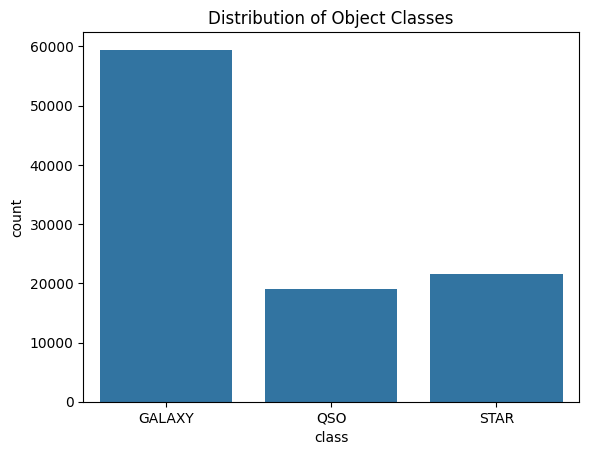

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='class')
plt.title('Distribution of Object Classes')
plt.show()


A box plot was used to compare the distribution of redshift for Stars, Galaxies and Quasars. redshift is an important property that describes how much light from an object has been shifted to longer wavelengths and is also related to distance.


The plot shows clear differences between the three object classes. Stars have redshift values that are all very close to zero, galaxies have moderate redshift values. Quasars have substantially higher redshift values and also display the largest range of values in thiss dataset.


Several outliers are visible, particularly within the quasar class where some objects reach redshift above 6. Despite the outliers, their is an clear distiction between the classes. This suggests that redshift is likely to be a highly informative feature for machine learning classification, as it provides different values between stars, galaxies and quasars


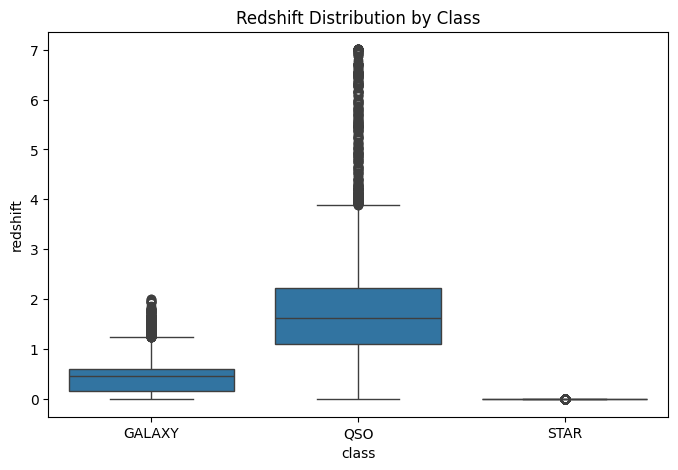

In [23]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='class', y='redshift')
plt.title('Redshift Distribution by Class')
plt.show()

Histograms were produced to show how common different ranges of values are for the features u, g, r, i and z,

The histograms show that most observations are concentrated within a relatively narrow range of values, suggesting that the features have well-defined distributions suitable for machine learning analysis. These provide an overview of ranges that appear most often in the dataset. this useful as these "features " will be used in machine learning

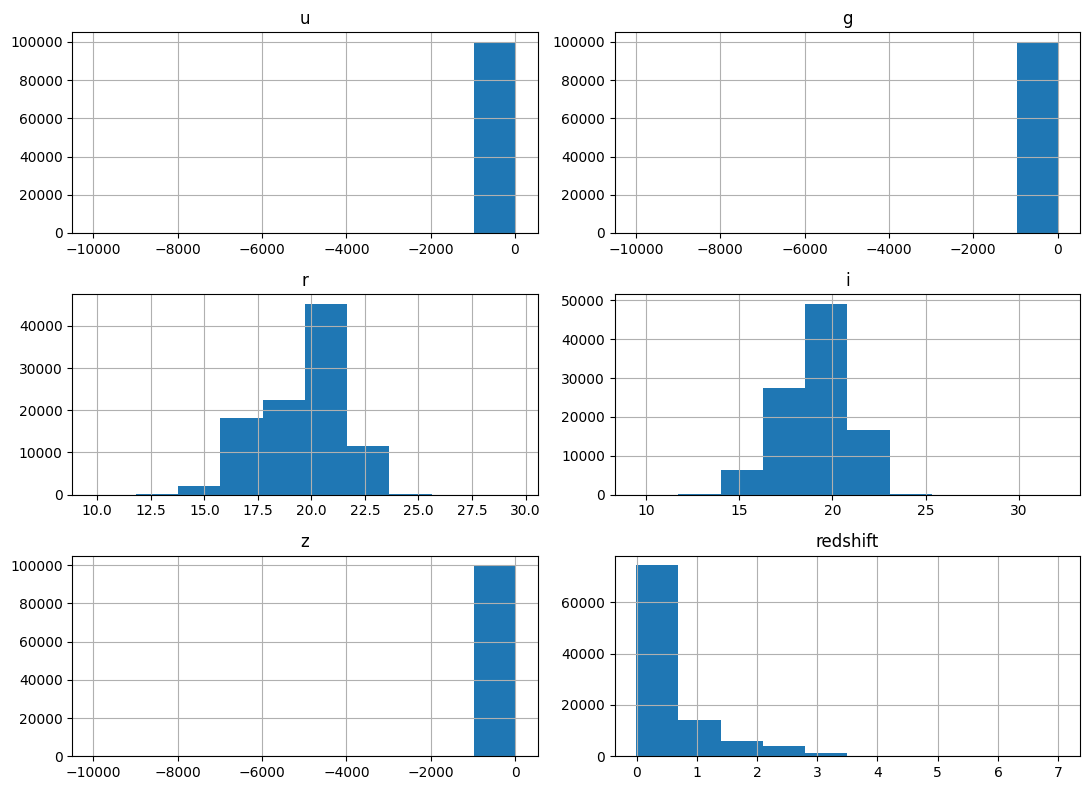

In [25]:
features = ['u', 'g', 'r', 'i', 'z', 'redshift']

df[features].hist(figsize=(11,8))
plt.tight_layout()
plt.show()

Two new features were calculated, (u-g) and (g-r), and these values are found by taking the difference in measurements recorded in different SDSS filters. Rather than looking at a single measurement, it allow us to compare how an objects appears across different parts of the spectrum.


The 'colour-colour' diagram plots (u-g) vs (g-r) for a sample of 10000 observationns in dataset and is coloured according to its class. if different classes have different regions covered, this diagram would contrain some usefil informsation to distiguish between classes

A very very much larger number of galaxy observations are visible compared with other classes, showing an imbalance observed earlier in the dataset.




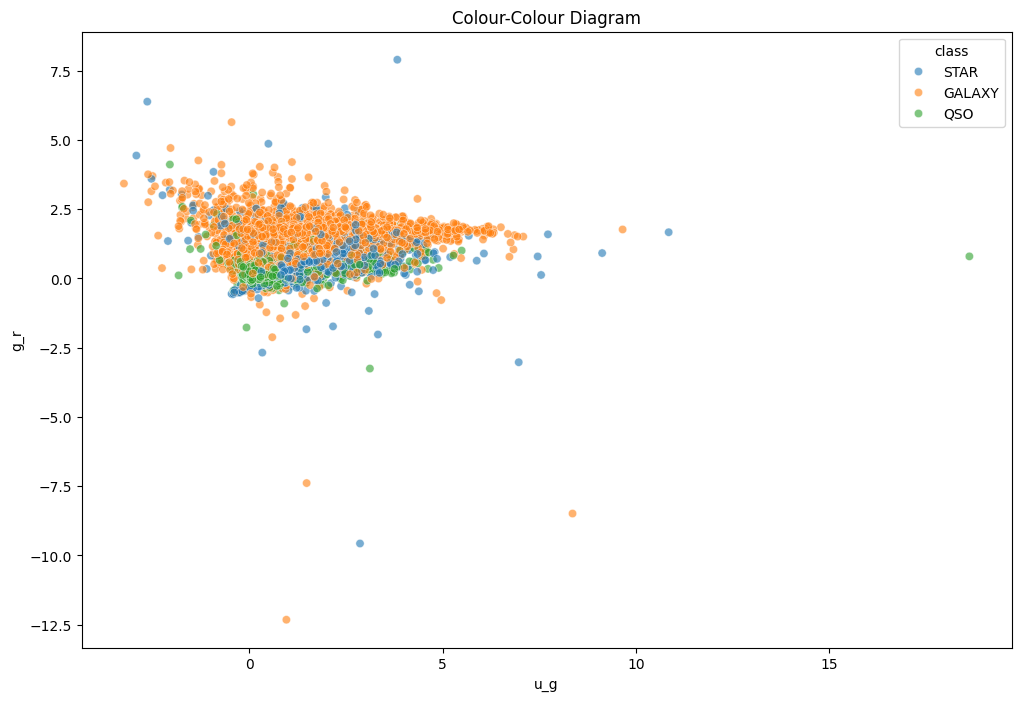

In [38]:
df['u_g'] = df['u'] - df['g']
df['g_r'] = df['g'] - df['r']

plt.figure(figsize=(12,8))

sns.scatterplot(
    data=df.sample(10000),
    x='u_g',
    y='g_r',
    hue='class',
    alpha=0.6
)

plt.title('Colour-Colour Diagram')
plt.show()

a pairplot is made with the features u , g, r,i ,z , redshift with a random sample of 2000 of the observationns. Thois shows the combinations of all the features simultanuosly, and also shows the distribution of each in the diagonal axis. all points are coloured by their classes. allowing me to see the similarities and differences between stars, galaxies, and quasars.

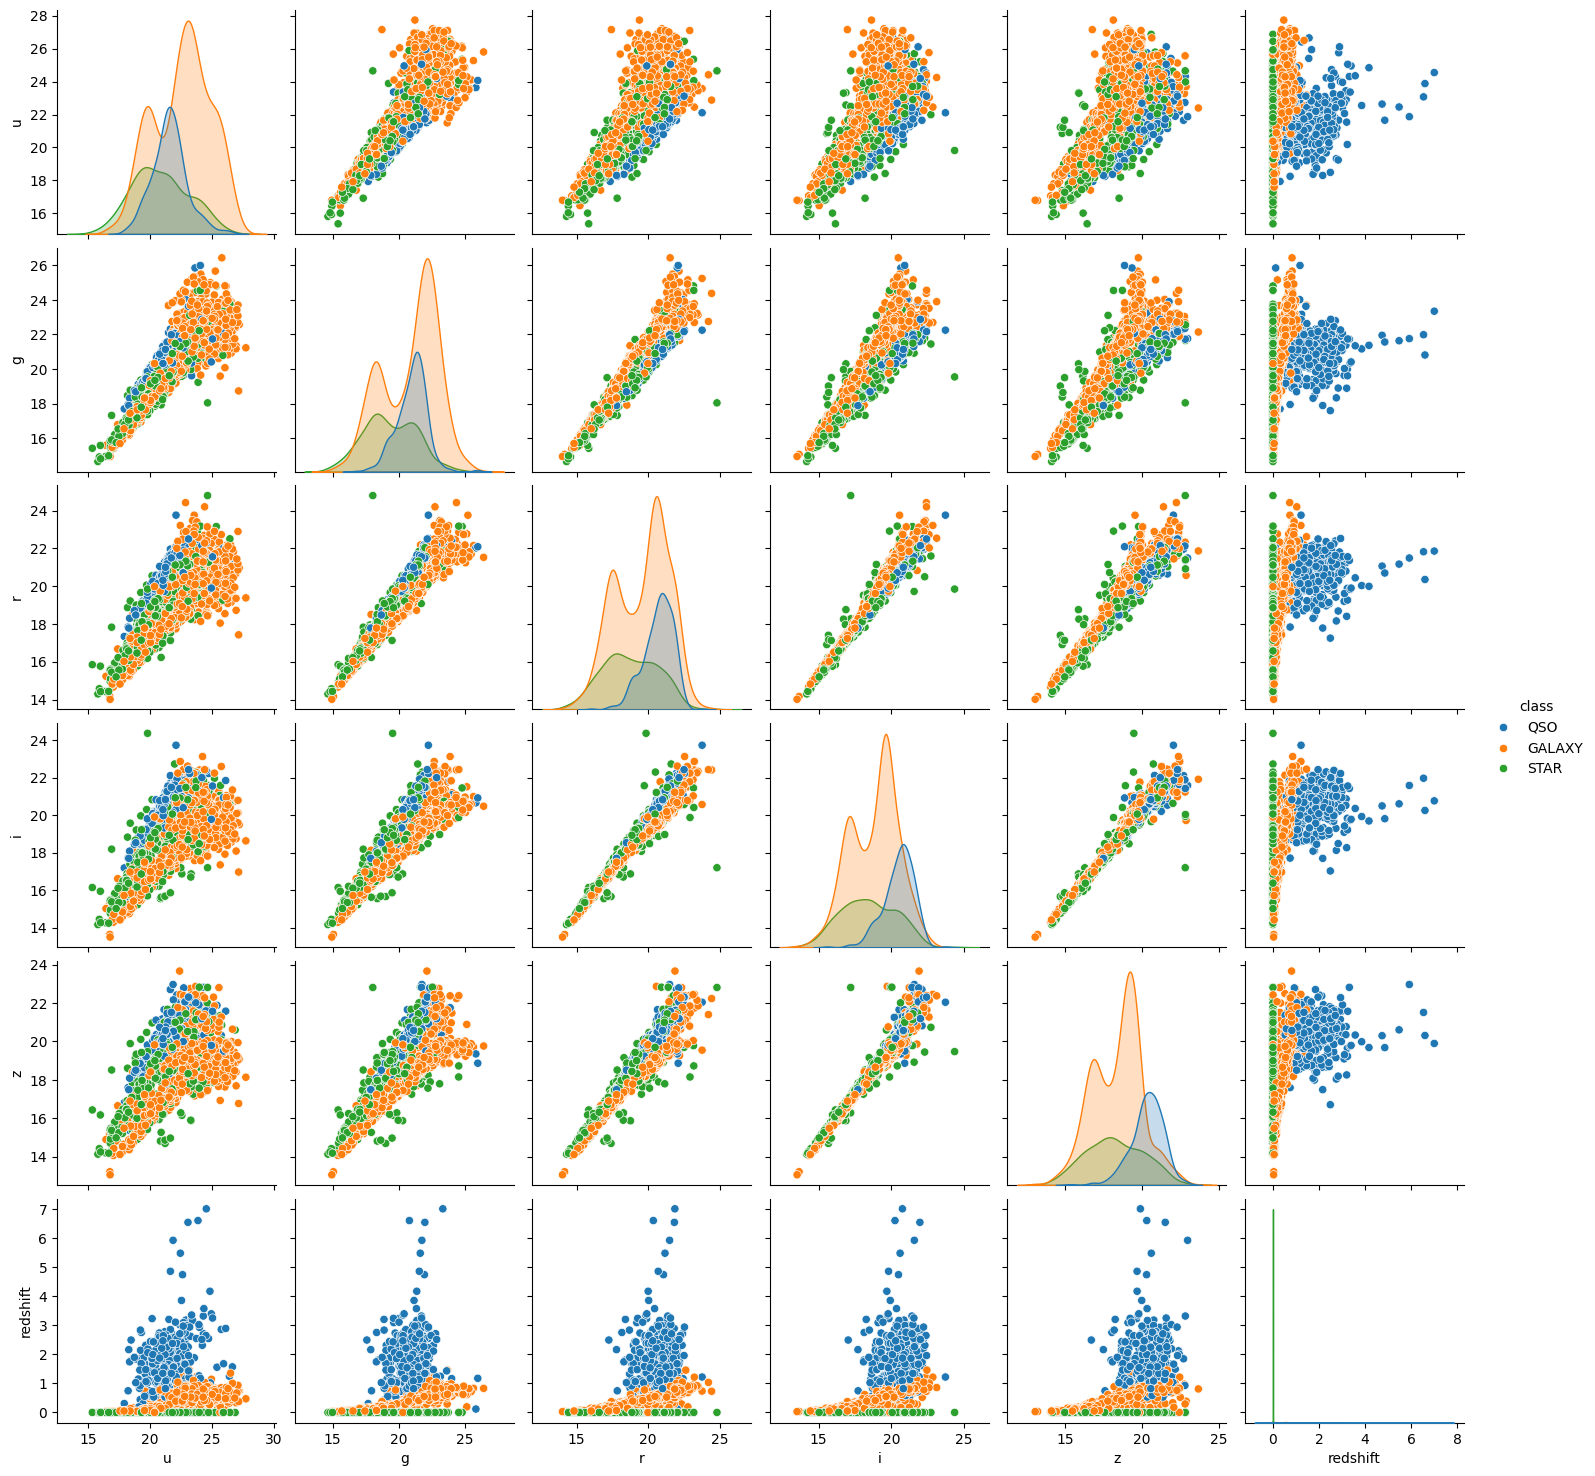

In [40]:
sample = df.sample(2000)

sns.pairplot(
    sample,
    vars=['u','g','r','i','z','redshift'],
    hue='class'
)

plt.show()